## Задание 3.1 Keras: Персептроны
Ознакомьтесь с возможностями Keras.
Загрузите встроенный набор цифр MNIST.
Создайте и обучите несколько небольших персептронов на 2-4 слоя с разными размерами слоёв.
Оцените результаты.

In [1]:
!pip install tensorflow


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

In [16]:
import seaborn as sns


In [3]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 12s 1us/step


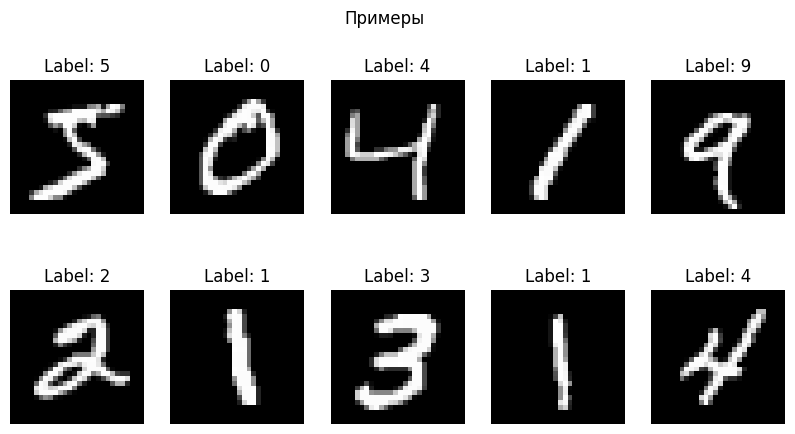

In [14]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.suptitle("Примеры")
plt.show()

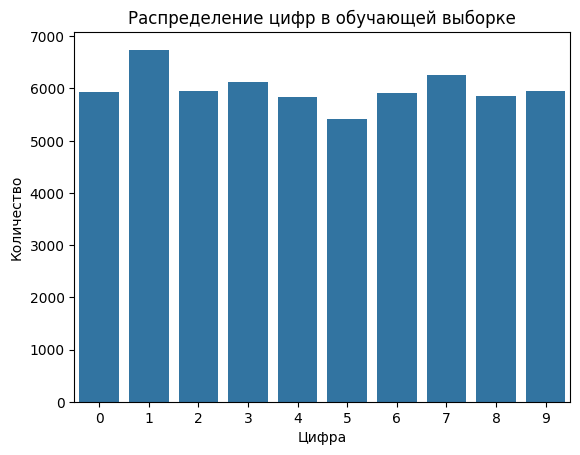

In [17]:
sns.countplot(x=y_train)
plt.title("Распределение цифр в обучающей выборке")
plt.xlabel("Цифра")
plt.ylabel("Количество")
plt.show()

нормализация

In [4]:
x_train = x_train / 255.0
x_test = x_test / 255.0

Выпрямление изображений: переводим изображения 28×28 в вектор длиной 784

In [5]:
x_train = x_train.reshape(-1, 784)
x_train.shape

(60000, 784)

In [6]:
x_test = x_test.reshape(-1, 784)
x_test.shape

(10000, 784)

### Функция для создания модели

In [7]:
def create_model(layer_sizes):
    model = keras.Sequential()
    
    # входной слой
    model.add(layers.Input(shape=(784,)))
    
    # скрытые слои
    for size in layer_sizes:
        model.add(layers.Dense(size, activation='relu'))
    
    # выходной слой
    model.add(layers.Dense(10, activation='softmax'))
    
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    
    return model

Модель 1 (простая, 2 слоя)

In [8]:
model1 = create_model([64])
history1 = model1.fit(x_train, y_train, epochs=5, validation_split=0.2, verbose=0)

Модель 2 (средняя, 3 слоя)

In [9]:
model2 = create_model([128, 64])
history2 = model2.fit(x_train, y_train, epochs=5, validation_split=0.2, verbose=0)

Модель 3 (глубже, 4 слоя)

In [10]:
model3 = create_model([256, 128, 64])
history3 = model3.fit(x_train, y_train, epochs=5, validation_split=0.2, verbose=0)

### Оценка моделей

In [11]:
loss1, acc1 = model1.evaluate(x_test, y_test, verbose=0)
loss2, acc2 = model2.evaluate(x_test, y_test, verbose=0)
loss3, acc3 = model3.evaluate(x_test, y_test, verbose=0)

print("Model 1 accuracy:", acc1)
print("Model 2 accuracy:", acc2)
print("Model 3 accuracy:", acc3)

Model 1 accuracy: 0.9668999910354614
Model 2 accuracy: 0.9692000150680542
Model 3 accuracy: 0.9733999967575073


### Визуализация

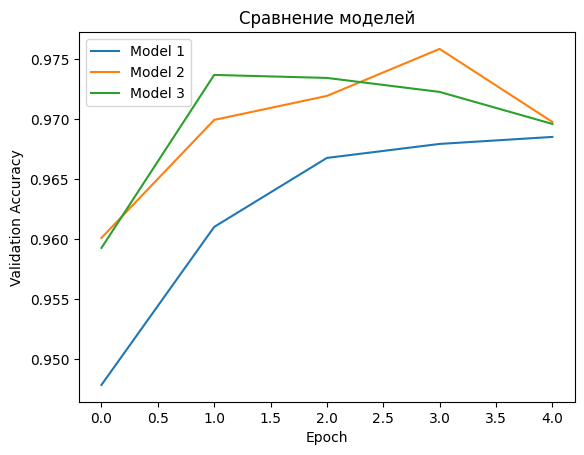

In [12]:
plt.plot(history1.history['val_accuracy'], label='Model 1')
plt.plot(history2.history['val_accuracy'], label='Model 2')
plt.plot(history3.history['val_accuracy'], label='Model 3')

plt.title('Сравнение моделей')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.show()

In [18]:
def plot_history(history, title):
    plt.figure(figsize=(12, 4))

    # accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='train')
    plt.plot(history.history['val_accuracy'], label='val')
    plt.title(f'{title} - Accuracy')
    plt.legend()

    # loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.title(f'{title} - Loss')
    plt.legend()

    plt.show()

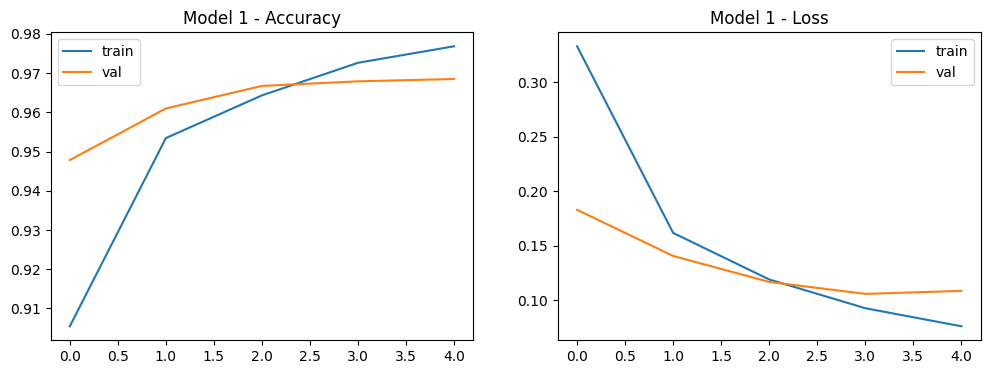

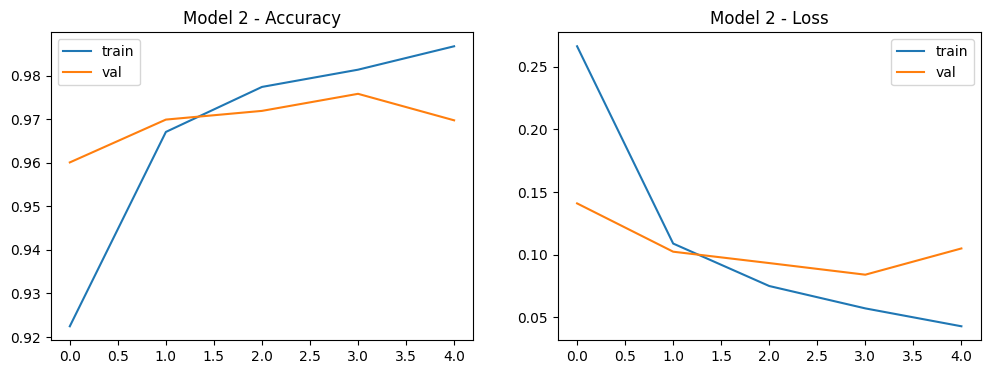

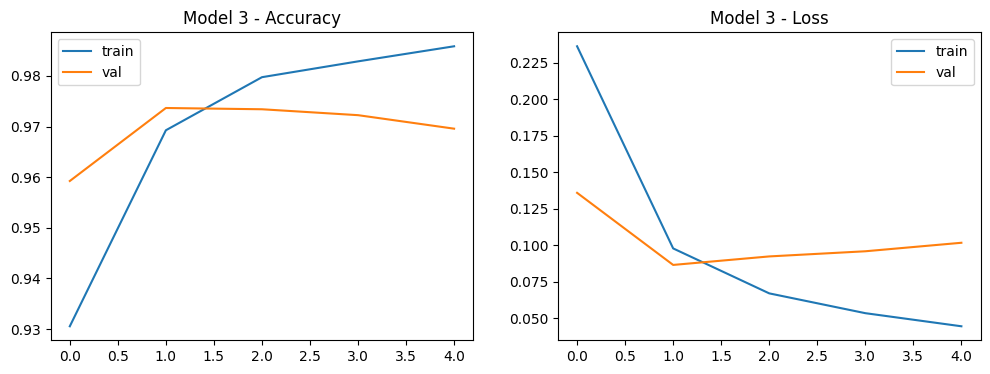

In [19]:
plot_history(history1, "Model 1")
plot_history(history2, "Model 2")
plot_history(history3, "Model 3")

In [22]:
from sklearn.metrics import confusion_matrix

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 554us/step


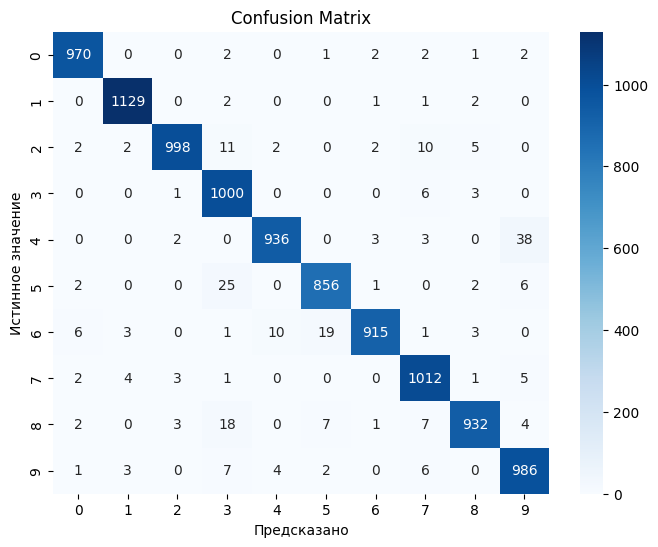

In [23]:
def plot_confusion_matrix(model, x_test, y_test):
    y_pred = model.predict(x_test)
    y_pred_classes = np.argmax(y_pred, axis=1)

    cm = confusion_matrix(y_test, y_pred_classes)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Предсказано")
    plt.ylabel("Истинное значение")
    plt.title("Confusion Matrix")
    plt.show()

plot_confusion_matrix(model3, x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 504us/step


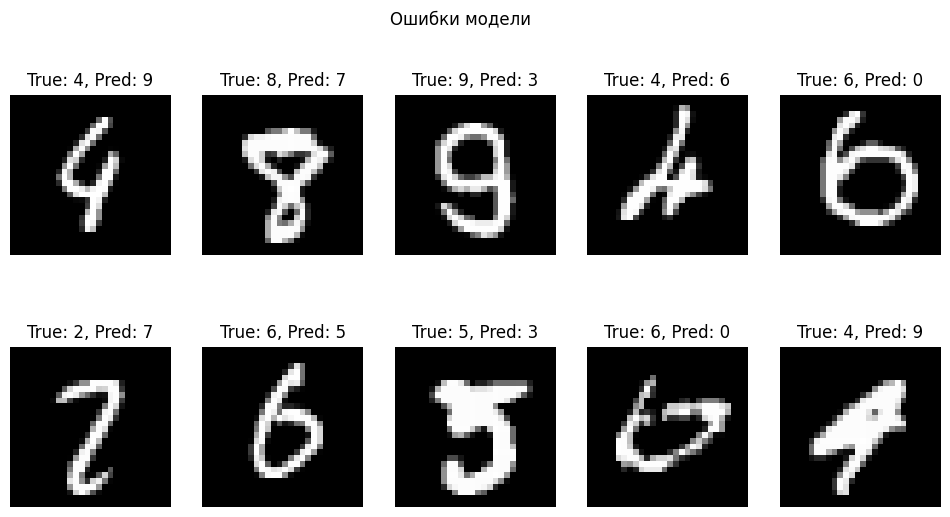

In [24]:
def show_misclassified(model, x_test, y_test, n=10):
    y_pred = model.predict(x_test)
    y_pred_classes = np.argmax(y_pred, axis=1)

    errors = np.where(y_pred_classes != y_test)[0]

    plt.figure(figsize=(12, 6))

    for i, idx in enumerate(errors[:n]):
        plt.subplot(2, 5, i + 1)
        plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
        plt.title(f"True: {y_test[idx]}, Pred: {y_pred_classes[idx]}")
        plt.axis('off')

    plt.suptitle("Ошибки модели")
    plt.show()

show_misclassified(model3, x_test, y_test)